# Día 6 — Backtesting, escenarios e interpretación

**Módulo 5: Econometría y Forecasting con IA — CEC EPN / Banco Central del Ecuador**  
**Fecha:** 11-11-2026 · **Unidades 4 y 5** · Contenidos 4.4, 4.5, 5.1 y 5.2 · **Inicio del proyecto final**

Hasta ahora hemos respondido "¿qué modelo se equivoca menos?". Un pronóstico que se entrega a quien toma decisiones necesita responder también:

- **¿Cuánto nos solemos equivocar** a 1, 2 y 3 meses? (backtesting)
- **¿Qué podría pasar** si las cosas salen mejor o peor de lo esperado? (escenarios)
- **¿Qué significa** el pronóstico en términos que entienda alguien que no es analista? (interpretación)
- **¿Cómo lo actualizo** el próximo mes sin rehacer todo a mano? (automatización, Módulo 4)

## Objetivos de la jornada

Al terminar deberías poder explicar, con tus propias palabras:

- qué es un **backtesting con origen móvil** y en qué se diferencia de la validación de los días anteriores;
- cómo medir si los **intervalos** de un modelo son confiables (**cobertura**);
- cómo construir escenarios **optimista, base y pesimista** a partir de los errores históricos;
- cómo traducir un pronóstico de inflación **mensual** en inflación **acumulada** y **anual**;
- cómo plantear el problema del proyecto final (5.1);
- cómo escribir una función que **actualice los datos** desde el BCE y regenere el pronóstico (5.2).

## Ruta del día

| Parte | Qué haremos |
|---|---|
| 1 | Datos y modelos finalistas |
| 2 | Backtesting con origen móvil a 1, 2 y 3 meses (4.4) |
| 3 | ¿Son confiables los intervalos? Cobertura (4.4) |
| 4 | Escenarios optimista, base y pesimista (4.4) |
| 5 | Interpretación económica: de mensual a anual (4.5) |
| 6 | Planteamiento del proyecto final (5.1) |
| 7 | Script de actualización de datos y reporte (5.2) |

# 0. Librerías

Además de las de siempre, usamos `requests` (Módulo 4) para descargar datos del BCE y `json` para leer su respuesta.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests                                   # descargas web (Módulo 4)

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Ubicamos la carpeta de datos sin depender de si Jupyter se abrió
# desde la carpeta raíz o desde la carpeta notebooks/.
DATA_DIR = Path('datos') if Path('datos').exists() else Path('../datos')

print('Usando datos desde:', DATA_DIR.resolve())

Usando datos desde: /tmp/m5repo/datos


In [3]:
series = pd.read_csv(DATA_DIR / 'series_economicas.csv', parse_dates=['fecha'], index_col='fecha').asfreq('MS')
y = series['ipc_var_mensual'].loc['2005':].dropna()
indice = series['ipc_indice'].dropna()

print(f'Inflación: {len(y)} meses, {y.index.min():%b %Y} – {y.index.max():%b %Y}')

Inflación: 260 meses, Jan 2005 – Aug 2026


# 1. Modelos finalistas

De los Días 1 a 5 elegimos cuatro candidatos para el pronóstico de los próximos tres meses. Todos se pueden reestimar en segundos, algo necesario para el backtesting:

| Modelo | Por qué entra | Día |
|---|---|---|
| Promedio móvil de 12 meses | la línea base más difícil de superar | 2 |
| ARIMA(1,0,0) | modelo estadístico simple, con intervalos | 3 |
| SARIMA(1,0,0)(1,0,0)₁₂ | mejor ajuste y residuos limpios | 3 |
| Promedio ARIMA + PM12 | combinación sencilla | 5 |

Dejamos fuera el Random Forest con variables macro: su mejora del Día 5 no se confirmó en validación, y reentrenarlo en cada origen hace el backtesting mucho más lento. En el proyecto puedes incluirlo si lo justificas.

**Qué vamos a hacer:** una función que, dada la historia hasta un origen, devuelva los pronósticos de los cuatro modelos a 1, 2 y 3 meses, más el intervalo del 80 % del ARIMA.

In [4]:
H = 3   # horizonte del proyecto final

def pronosticar(historia, h=H):
    """Pronósticos de los modelos finalistas para los h meses siguientes al final de `historia`."""
    pm12 = np.repeat(historia.iloc[-12:].mean(), h)

    arima = ARIMA(historia, order=(1, 0, 0), trend='c').fit()
    f_arima = arima.get_forecast(steps=h)
    intervalo = f_arima.conf_int(alpha=0.20).values         # 80 %

    sarima = ARIMA(historia, order=(1, 0, 0), seasonal_order=(1, 0, 0, 12), trend='c').fit()

    return pd.DataFrame({
        'Promedio móvil 12': pm12,
        'ARIMA(1,0,0)': f_arima.predicted_mean.values,
        'SARIMA': sarima.get_forecast(steps=h).predicted_mean.values,
        'Promedio ARIMA + PM12': (pm12 + f_arima.predicted_mean.values) / 2,
        'ARIMA_inf80': intervalo[:, 0],
        'ARIMA_sup80': intervalo[:, 1],
    }, index=pd.Index(range(1, h + 1), name='h'))

pronosticar(y.loc[:'2024-12']).round(3)

,Promedio móvil 12,"ARIMA(1,0,0)",SARIMA,Promedio ARIMA + PM12,ARIMA_inf80,ARIMA_sup80
h,,,,,,
1,0.046,-0.294,-0.273,-0.124,-0.722,0.134
2,0.046,-0.002,-0.015,0.022,-0.466,0.463
3,0.046,0.122,0.161,0.084,-0.349,0.593


**Qué obtuvimos:** desde diciembre de 2024, los pronósticos de enero, febrero y marzo de 2025 ($h = 1, 2, 3$). El promedio móvil repite el mismo valor; ARIMA se acerca a su media; SARIMA cambia según el mes del año.

# 2. Backtesting con origen móvil (4.4)

## 2.1 ¿Qué es y en qué se diferencia de la validación?

**Backtesting** significa "probar hacia atrás": simular qué habría pasado si hubiéramos usado el método en el pasado, **reestimándolo en cada origen** con la información disponible en ese momento, exactamente como lo haríamos en la práctica cada mes.

| | Validación (Días 2–5) | Backtesting (hoy) |
|---|---|---|
| Para qué | **elegir** modelo e hiperparámetros | **medir** cuánto se equivoca el método elegido |
| Parámetros | fijos o pocos reajustes | **se reestiman en cada origen** |
| Horizonte | casi siempre 1 mes | **1, 2 y 3 meses**, los que se van a entregar |
| Periodo | antes del Test | **toda la historia útil**, incluido 2025–2026 |

Usar el periodo 2025–2026 hoy es válido porque **ya no vamos a elegir modelos con él**: solo queremos describir la incertidumbre del procedimiento.

## 2.2 El procedimiento, paso a paso

Para cada mes desde enero de 2015 hasta mayo de 2026 (137 orígenes):

1. tomar la historia **hasta ese mes**;
2. reestimar los modelos;
3. pronosticar los 3 meses siguientes;
4. guardar el pronóstico y el valor real.

Son 137 × 2 = 274 estimaciones de ARIMA: tarda unos 20 segundos.

In [5]:
origenes = pd.date_range('2015-01-01', y.index.max() - pd.DateOffset(months=H), freq='MS')

filas = []
for origen in origenes:
    pron = pronosticar(y.loc[:origen])
    for h in pron.index:
        mes = origen + pd.DateOffset(months=h)
        filas.append({'origen': origen, 'mes': mes, 'h': h, 'real': y.loc[mes], **pron.loc[h].to_dict()})

backtest = pd.DataFrame(filas)
print('Orígenes:', len(origenes), '· pronósticos guardados:', len(backtest))
backtest.head(3).round(3)

Orígenes: 137 · pronósticos guardados: 411


,origen,mes,h,real,Promedio móvil 12,"ARIMA(1,0,0)",SARIMA,Promedio ARIMA + PM12,ARIMA_inf80,ARIMA_sup80
0,2015-01-01,2015-02-01,1,0.612,0.29,0.455,0.288,0.373,0.057,0.853
1,2015-01-01,2015-03-01,2,0.414,0.29,0.394,0.517,0.342,-0.042,0.831
2,2015-01-01,2015-04-01,3,0.837,0.29,0.367,0.333,0.328,-0.077,0.810


**Qué obtuvimos:** una tabla con una fila por pronóstico: el origen desde el que se hizo, el mes pronosticado, el horizonte, el valor real y lo que dijo cada modelo. Con esta tabla podemos responder casi cualquier pregunta sobre el error.

## 2.3 Error por horizonte

In [6]:
MODELOS = ['Promedio móvil 12', 'ARIMA(1,0,0)', 'SARIMA', 'Promedio ARIMA + PM12']

for m in MODELOS:
    backtest[f'error_{m}'] = backtest['real'] - backtest[m]

mae_h = pd.DataFrame({m: backtest.groupby('h')[f'error_{m}'].apply(lambda e: e.abs().mean()) for m in MODELOS})
mae_h.round(3)

,Promedio móvil 12,"ARIMA(1,0,0)",SARIMA,Promedio ARIMA + PM12
h,,,,
1,0.255,0.269,0.268,0.252
2,0.257,0.284,0.265,0.259
3,0.258,0.287,0.262,0.260


### Lectura

- El **promedio móvil de 12** y el **promedio ARIMA + PM12** tienen el menor error en los tres horizontes (≈ 0.25–0.26).
- **ARIMA(1,0,0)** empeora un poco con el horizonte (de ≈ 0.27 a ≈ 0.29).
- El **SARIMA** se mantiene estable (≈ 0.26–0.27).
- Las diferencias entre modelos son de **centésimas**. La conclusión de toda la semana se confirma: en la inflación mensual del Ecuador, el ruido domina y los métodos sensatos se equivocan parecido.

**Elección para el pronóstico base:** el **promedio ARIMA + PM12**. Se equivoca igual que el mejor, combina un método estadístico con la línea base y, a diferencia del promedio móvil solo, reacciona a los últimos meses.

## 2.4 ¿Cuándo se equivoca más?

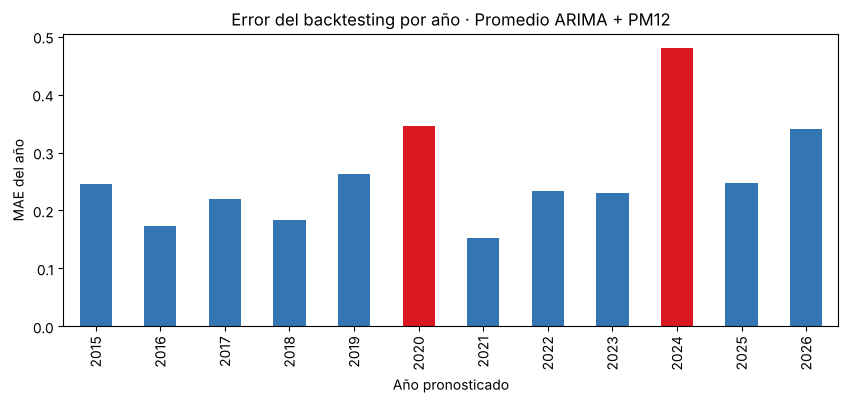

mes,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
MAE,0.246,0.173,0.22,0.184,0.263,0.346,0.153,0.234,0.23,0.481,0.247,0.34


In [7]:
modelo_base = 'Promedio ARIMA + PM12'
mae_anual = backtest.groupby(backtest['mes'].dt.year)[f'error_{modelo_base}'].apply(lambda e: e.abs().mean())

fig, ax = plt.subplots(figsize=(10, 3.8))
mae_anual.plot.bar(ax=ax, color=['#DA181E' if a in (2020, 2024) else '#3476B1' for a in mae_anual.index])
ax.set_ylabel('MAE del año')
ax.set_xlabel('Año pronosticado')
ax.set_title(f'Error del backtesting por año · {modelo_base}')
plt.show()

mae_anual.round(3).to_frame('MAE').T

**Lectura:** en un año normal el error típico ronda 0.15–0.25 puntos, pero en **2020 (pandemia)** sube a ≈ 0.35 y en **2024 (IVA y otros choques)** a ≈ 0.48, el doble de lo habitual. (2026 tiene solo cinco meses evaluados, entre ellos mayo y junio, con variaciones de −0.62 y +0.79.) Eso hay que comunicarlo: el modelo funciona razonablemente en años normales y **se equivoca mucho cuando hay choques**, que por definición no se pueden anticipar con el pasado.

## 2.5 ¿Hay sesgo?

In [8]:
sesgo = backtest.groupby('h')[f'error_{modelo_base}'].mean()
print('Error medio (real − pronóstico) por horizonte:')
print(sesgo.round(3).to_string())

Error medio (real − pronóstico) por horizonte:
h
1   -0.046
2   -0.071
3   -0.083


**Lectura:** el error medio es negativo y pequeño (entre ≈ −0.05 y ≈ −0.08, y crece con el horizonte): el método pronosticó, en promedio, **un poco más** de inflación de la que hubo. El sesgo es bastante menor que el error típico (≈ 0.26), así que no lo corregimos, pero conviene mencionarlo en el informe.

# 3. ¿Son confiables los intervalos? (4.4)

## 3.1 Cobertura

Un intervalo del 80 % promete que **8 de cada 10 veces** el valor real caerá dentro. Con el backtesting podemos comprobar si cumple: contamos en qué porcentaje de los pronósticos el real quedó dentro del intervalo. A eso se le llama **cobertura**.

| Cobertura observada | Lectura |
|---|---|
| ≈ 80 % | el intervalo está bien calibrado |
| mucho menos de 80 % | el modelo es **demasiado optimista**: subestima la incertidumbre |
| mucho más de 80 % | el intervalo es innecesariamente ancho |

In [9]:
dentro = (backtest['real'] >= backtest['ARIMA_inf80']) & (backtest['real'] <= backtest['ARIMA_sup80'])

cobertura = dentro.groupby(backtest['h']).mean() * 100
print('Cobertura del intervalo del 80 % de ARIMA, por horizonte:')
print(cobertura.round(1).astype(str).add(' %').to_string())
print('\nAncho medio del intervalo:', round((backtest['ARIMA_sup80'] - backtest['ARIMA_inf80']).mean(), 2), 'puntos')

Cobertura del intervalo del 80 % de ARIMA, por horizonte:
h
1    78.8 %
2    80.3 %
3    79.6 %

Ancho medio del intervalo: 0.86 puntos


**Lectura:** la cobertura es ≈ 79–80 % en los tres horizontes: **los intervalos de ARIMA están bien calibrados**. Aunque el Día 3 vimos que los residuos no son normales, en conjunto el intervalo cumple lo que promete. El ancho medio, ≈ 0.86 puntos, es la incertidumbre honesta de un pronóstico mensual de inflación.

## 3.2 Intervalos empíricos

Hay otra forma de construir un intervalo que **no depende de ningún supuesto**: usar directamente los errores del backtesting. Si el 10 % de los errores fue menor que −0.40 y el 10 % mayor que +0.30, un intervalo empírico del 80 % es:

$$
[\,\hat y + q_{10\%},\;\; \hat y + q_{90\%}\,]
$$

Sirve para cualquier modelo, incluido un promedio o un Random Forest, que no tienen intervalos propios.

In [10]:
cuantiles = backtest.groupby('h')[f'error_{modelo_base}'].quantile([0.10, 0.50, 0.90]).unstack()
cuantiles.columns = ['q10', 'q50', 'q90']
cuantiles.round(3)

,q10,q50,q90
h,,,
1,-0.40,-0.052,0.296
2,-0.40,-0.064,0.327
3,-0.42,-0.082,0.322


**Lectura:** para el modelo base, el 80 % central de los errores va de ≈ −0.40 a ≈ +0.30–0.33 puntos. El intervalo es **asimétrico**: los errores negativos (inflación menor que la pronosticada) han sido más grandes que los positivos. Esto viene de los meses de deflación de 2020 y de 2024.

# 4. Escenarios optimista, base y pesimista (4.4)

## 4.1 ¿Qué es un escenario?

Un **escenario** es una historia coherente sobre el futuro, con su cifra. A quien toma decisiones le sirve más "si la inflación se comporta como en sus meses buenos, llegaríamos a X; si se comporta como en sus meses malos, a Y" que un intervalo abstracto.

Construiremos tres:

| Escenario | Cómo se construye | Lectura |
|---|---|---|
| **Base** | pronóstico del modelo elegido | lo más probable según la historia reciente |
| **Optimista** | base + cuantil 10 % de los errores | inflación más baja de lo esperado (como en 1 de cada 10 meses del pasado) |
| **Pesimista** | base + cuantil 90 % de los errores | inflación más alta de lo esperado |

> "Optimista" aquí significa **menos inflación**. Para un exportador o un deudor, la lectura podría ser distinta; hay que aclararlo siempre en el informe.

Agregamos un cuarto escenario **de choque**, inspirado en el Día 3: ¿qué pasaría si en octubre de 2026 ocurriera un aumento de precios como el del IVA de 2024 (≈ +1.1 puntos)?

**Qué vamos a hacer:** pronosticar septiembre–noviembre de 2026 con toda la historia y armar los cuatro escenarios.

In [11]:
pron_final = pronosticar(y)
meses_futuros = pd.date_range(y.index.max() + pd.DateOffset(months=1), periods=H, freq='MS')

escenarios = pd.DataFrame({
    'Optimista': pron_final[modelo_base].values + cuantiles['q10'].values,
    'Base': pron_final[modelo_base].values,
    'Pesimista': pron_final[modelo_base].values + cuantiles['q90'].values,
}, index=meses_futuros)

# Escenario de choque: el base, más un efecto de 1.1 puntos en el segundo mes.
choque = escenarios['Base'].copy()
choque.iloc[1] += 1.1
escenarios['Choque de precios en el mes 2'] = choque

escenarios.round(2)

,Optimista,Base,Pesimista,Choque de precios en el mes 2
2026-09-01,-0.28,0.12,0.42,0.12
2026-10-01,-0.26,0.14,0.47,1.24
2026-11-01,-0.27,0.15,0.47,0.15


**Cómo leer la tabla:** para septiembre de 2026 el escenario base es ≈ 0.12 %; el optimista, ≈ −0.28 % (deflación); el pesimista, ≈ 0.42 %. El escenario de choque coincide con el base salvo en octubre, donde sube a ≈ 1.2 %.

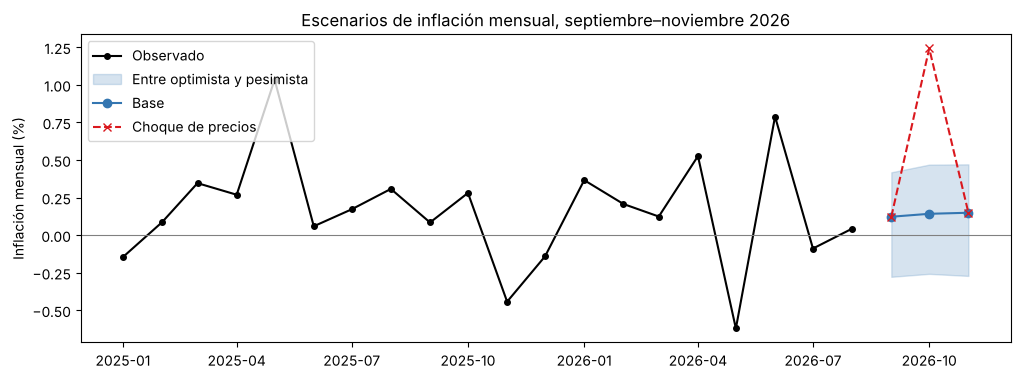

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.loc['2025-01':], color='black', marker='o', markersize=4, label='Observado')
ax.fill_between(escenarios.index, escenarios['Optimista'], escenarios['Pesimista'], color='#3476B1', alpha=0.2,
                label='Entre optimista y pesimista')
ax.plot(escenarios['Base'], color='#3476B1', marker='o', label='Base')
ax.plot(escenarios['Choque de precios en el mes 2'], color='#DA181E', linestyle='--', marker='x', label='Choque de precios')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_ylabel('Inflación mensual (%)')
ax.set_title('Escenarios de inflación mensual, septiembre–noviembre 2026')
ax.legend(loc='upper left')
plt.show()

# 5. Interpretación económica: de mensual a anual (4.5)

## 5.1 Por qué traducir

Una inflación mensual de 0.10 % no le dice mucho a alguien que negocia un salario o una tasa de interés. Lo habitual es hablar de **inflación anual**: cuánto subieron los precios en los últimos 12 meses.

## 5.2 Del pronóstico mensual al índice

Si conocemos el índice de agosto de 2026 y pronosticamos las variaciones de septiembre, octubre y noviembre, el índice futuro se obtiene **encadenando** las variaciones:

$$
IPC_{\text{nov}} = IPC_{\text{ago}} \times \left(1 + \frac{\pi_{\text{sep}}}{100}\right) \times \left(1 + \frac{\pi_{\text{oct}}}{100}\right) \times \left(1 + \frac{\pi_{\text{nov}}}{100}\right)
$$

y la inflación anual de noviembre es:

$$
\pi^{\text{anual}}_{\text{nov 2026}} = \left(\frac{IPC_{\text{nov 2026}}}{IPC_{\text{nov 2025}}} - 1\right) \times 100
$$

### A mano, escenario base

Con $IPC_{\text{ago}} = 100.84$ y las variaciones del escenario base (0.12 %, 0.14 % y 0.15 %):

$$
IPC_{\text{nov}} = 100.84 \times 1.0012 \times 1.0014 \times 1.0015 = 101.25
$$

Como $IPC_{\text{nov 2025}} = 99.64$:

$$
\pi^{\text{anual}}_{\text{nov 2026}} = \left(\frac{101.25}{99.64} - 1\right) \times 100 = 1.62\,\%
$$

In [13]:
def inflacion_anual_proyectada(variaciones_mensuales):
    """Encadena las variaciones mensuales sobre el último índice y calcula la inflación anual del último mes."""
    indice_futuro = indice.iloc[-1] * np.cumprod(1 + np.asarray(variaciones_mensuales) / 100)
    meses = pd.date_range(indice.index[-1] + pd.DateOffset(months=1), periods=len(variaciones_mensuales), freq='MS')
    indice_futuro = pd.Series(indice_futuro, index=meses)
    hace_12 = indice.loc[meses - pd.DateOffset(months=12)].values
    return pd.DataFrame({'indice': indice_futuro, 'inflacion_anual_%': (indice_futuro.values / hace_12 - 1) * 100}, index=meses)

print('Índice de agosto 2026:', round(indice.iloc[-1], 2))
print('Inflación anual de agosto 2026 (observada):', round((indice.iloc[-1] / indice.loc['2025-08-01'] - 1) * 100, 2), '%')

traduccion = pd.DataFrame({
    nombre: inflacion_anual_proyectada(escenarios[nombre])['inflacion_anual_%']
    for nombre in escenarios.columns
})
traduccion.round(2)

Índice de agosto 2026: 100.84
Inflación anual de agosto 2026 (observada): 1.12 %


,Optimista,Base,Pesimista,Choque de precios en el mes 2
2026-09-01,0.75,1.16,1.46,1.16
2026-10-01,0.21,1.02,1.65,2.13
2026-11-01,0.39,1.62,2.58,2.74


### Cómo leer la tabla

Cada celda es la **inflación anual** que resultaría en ese mes si se cumpliera el escenario. Para **noviembre de 2026**:

- escenario **base**: la inflación anual estaría cerca de 1.6 %;
- **optimista**: bajaría a alrededor de 0.4 %;
- **pesimista**: subiría a alrededor de 2.6 %;
- **choque de precios**: llegaría a alrededor de 2.7 %, porque un solo mes con un aumento como el del IVA se arrastra en la inflación anual durante 12 meses.

## 5.3 Un párrafo para quien decide

Un buen informe ejecutivo responde en pocas líneas **qué**, **cuánto**, **qué tan seguro** y **qué hacer**:

> **Pronóstico de inflación, septiembre–noviembre 2026.** Con datos del INEC hasta agosto, esperamos una inflación mensual cercana a 0.1 % en los próximos tres meses, lo que llevaría la inflación anual de noviembre a alrededor de 1.6 % (escenario base). La incertidumbre es alta: en el pasado, 8 de cada 10 valores reales quedaron entre 0.4 puntos por debajo y 0.3 puntos por encima del pronóstico, por lo que la inflación anual de noviembre podría estar entre 0.4 % y 2.6 %. El pronóstico no anticipa choques como cambios de impuestos o de precios regulados; si se anunciara uno, la inflación anual podría superar el 2.5 %. Recomendamos actualizar el pronóstico con cada publicación mensual del INEC.

Fíjate en lo que **no** dice: no habla de AIC, de SARIMA ni de MAE. Esos detalles van en un anexo técnico.

# 6. Planteamiento del proyecto final (5.1)

El proyecto **"Pronosticando la economía"** (40 puntos, individual) se desarrolla hoy y mañana con el notebook `07_Dia7_Taller_Proyecto.ipynb`. Eliges **una** de tres series:

| Opción | Columna | Fuente | Desde | Observaciones |
|---|---|---|---|---:|
| 1. Inflación mensual | `ipc_var_mensual` | INEC | 2005 (útil) | 260 |
| 2. Tasa activa referencial | `tasa_activa_ref_pct` | BCE | 2015 | 143 |
| 3. Balanza comercial | `balanza_comercial_musd` | BCE | 1990 | 440 |

**Qué vamos a hacer:** mirar las tres series para que puedas elegir con información.

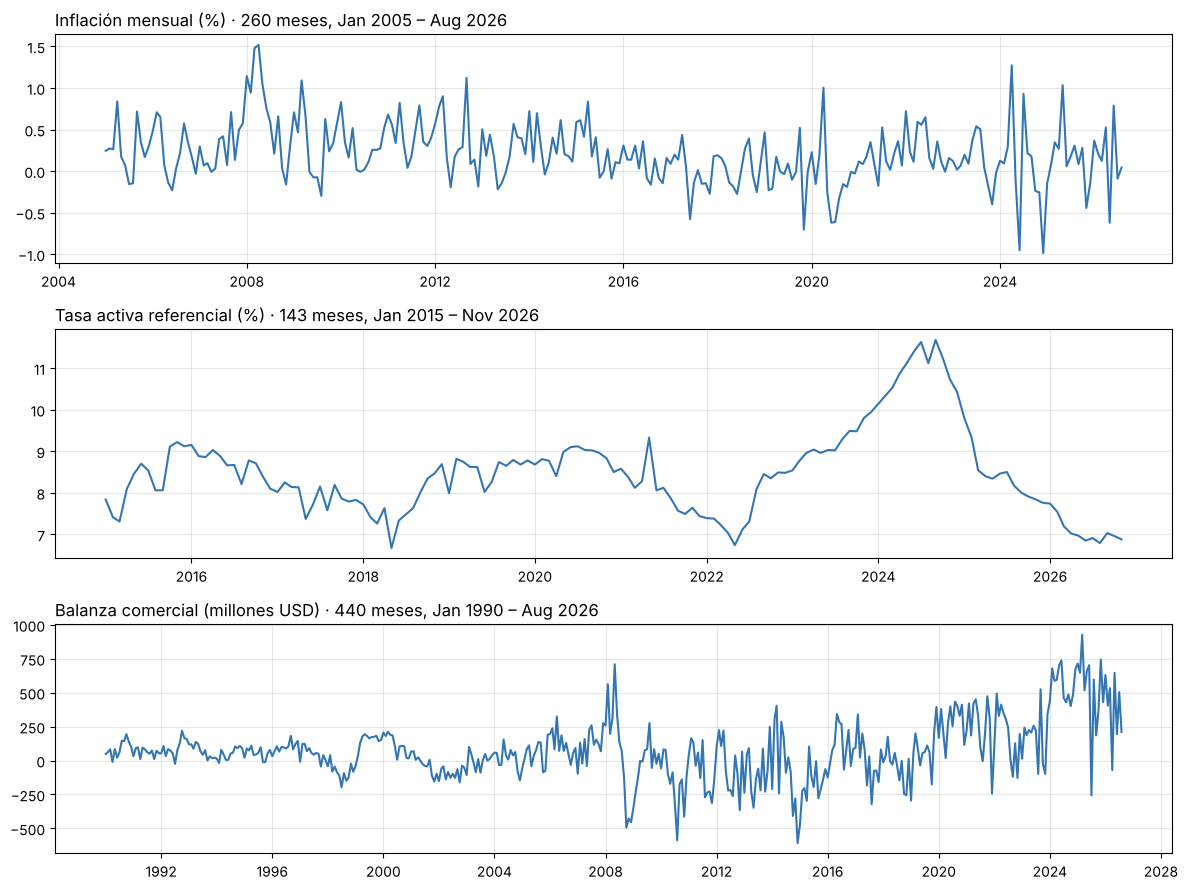

In [14]:
opciones = {
    'ipc_var_mensual': ('Inflación mensual (%)', '2005'),
    'tasa_activa_ref_pct': ('Tasa activa referencial (%)', '2015'),
    'balanza_comercial_musd': ('Balanza comercial (millones USD)', '1990'),
}

fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, (col, (titulo, desde)) in zip(axes, opciones.items()):
    s = series[col].loc[desde:].dropna()
    ax.plot(s, color='#3476B1')
    ax.set_title(f'{titulo} · {len(s)} meses, {s.index.min():%b %Y} – {s.index.max():%b %Y}', loc='left')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Qué tener en cuenta al elegir

| Serie | Característica | Pista de modelo |
|---|---|---|
| Inflación | ruidosa, estacional, choques en 2020 y 2024 | promedio móvil, SARIMA, promedio de modelos |
| Tasa activa | **persistente**, con tendencia por tramos y pocos datos | ingenuo (ganó el Día 1), ARIMA con $d = 1$ |
| Balanza comercial | volátil, cambia de signo, influida por el petróleo | promedio móvil (ganó el Día 1), RF con variables de petróleo |

### La ficha del problema

Antes de programar, escribe en la primera celda del notebook del proyecto:

1. **Pregunta:** ¿qué quiero pronosticar y para quién? (por ejemplo, "la tasa activa de los próximos tres meses, para un área de crédito").
2. **Unidad y frecuencia.**
3. **Horizonte:** 3 meses.
4. **Periodo de entrenamiento** y su justificación (Día 5, parte 8).
5. **Métrica principal:** MAE (y RMSE como complemento).
6. **Línea base:** el pronóstico simple que debes superar.

# 7. Script de actualización de datos (5.2)

## 7.1 El problema

Cada mes el INEC y el BCE publican datos nuevos. Si el pronóstico se rehace a mano, se pierde tiempo y se cometen errores. En el Módulo 4 aprendimos a **consumir APIs** y a **automatizar procesos**; ahora lo aplicamos.

## 7.2 La API del BCE

El portal **BCEData** del Banco Central publica la Información Estadística Mensual a través de un servicio web que devuelve JSON. Lo usamos para construir `series_economicas.csv`.

| Recurso | Dirección | Devuelve |
|---|---|---|
| Catálogo | `.../wp-json/bcedata/v1/tree` | la lista de grupos de series (`id_grupo`) |
| Grupo | `.../wp-json/bcedata/v1/bundle/{id_grupo}` | frecuencias, unidades y nombres de las series del grupo |
| Datos | `.../wp-json/bcedata/v1/grid?id_grupo=..&frecuencia=..&unidad=..&desde=..&hasta=..` | los valores, una fila por serie |

Por ejemplo, el grupo **71** es la balanza comercial mensual, y el **49** las tasas de interés referenciales.

## 7.3 La función de descarga

**Qué vamos a hacer:** escribir una función que pida un grupo del BCE y devuelva una serie de Pandas. La diseñamos para que **nunca rompa el notebook**: si no hay conexión o el servicio no responde, avisa y devuelve `None`.

In [15]:
URL_BCE = 'https://contenido.bce.fin.ec/wp-json/bcedata/v1'

MESES = {'Ene': 1, 'Feb': 2, 'Mar': 3, 'Abr': 4, 'May': 5, 'Jun': 6,
         'Jul': 7, 'Ago': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dic': 12}

def descargar_serie_bce(id_grupo, ruta_serie, unidad, desde='2000-01', hasta='2030-12', timeout=15):
    """Descarga una serie mensual del BCE. Devuelve una Serie con índice mensual, o None si falla."""
    parametros = {'id_grupo': id_grupo, 'frecuencia': 'Mensual', 'unidad': unidad, 'desde': desde, 'hasta': hasta}
    try:
        respuesta = requests.get(f'{URL_BCE}/grid', params=parametros, timeout=timeout)
        respuesta.raise_for_status()                       # error si el código HTTP no es 200
        datos = respuesta.json()
    except Exception as error:
        print(f'No se pudo descargar el grupo {id_grupo}: {type(error).__name__}')
        return None

    for fila in datos.get('rows', []):
        if fila.get('tipo') == 'Series' and fila.get('ruta') == ruta_serie:
            valores = {
                pd.Timestamp(int(periodo.split()[1]), MESES[periodo.split()[0]], 1): valor
                for periodo, valor in fila['values'].items() if valor is not None
            }
            return pd.Series(valores).sort_index().asfreq('MS')

    print(f'La serie "{ruta_serie}" no está en el grupo {id_grupo}.')
    return None

### Cómo funciona, línea por línea

1. `requests.get(..., params=..., timeout=15)`: arma la dirección con los parámetros y espera como máximo 15 segundos.
2. `raise_for_status()`: si el servidor responde con error (404, 500…), lanza una excepción.
3. `respuesta.json()`: convierte el texto JSON en un diccionario de Python.
4. El bloque `try / except` captura **cualquier** error (sin internet, servidor caído, formato inesperado) y devuelve `None` en lugar de detener el notebook.
5. Se busca la fila cuya `ruta` coincide con la serie pedida y se convierten sus claves (`"Ene 2025"`) en fechas.

## 7.4 Actualizar y combinar con los datos locales

**Qué vamos a hacer:** intentar descargar la balanza comercial y la tasa activa, y si funciona, combinar lo nuevo con lo que ya tenemos. Si no hay conexión, seguimos con el archivo local.

In [16]:
SERIES_BCE = {
    'balanza_comercial_musd': dict(id_grupo=71, ruta_serie='balanza comercial\\total balanza comercial',
                                   unidad='Millones de USD'),
    'tasa_activa_ref_pct': dict(id_grupo=49, ruta_serie='vigencia mensual\\activa', unidad='Porcentaje'),
}

def actualizar_series(series_locales):
    """Intenta actualizar cada serie del BCE; conserva los datos locales si la descarga falla."""
    actualizadas = series_locales.copy()
    for columna, parametros in SERIES_BCE.items():
        nueva = descargar_serie_bce(**parametros)
        if nueva is None:
            print(f'{columna}: se mantiene el archivo local (último dato {series_locales[columna].last_valid_index():%b %Y}).')
            continue
        actualizadas = actualizadas.reindex(actualizadas.index.union(nueva.index))
        actualizadas[columna] = nueva.combine_first(actualizadas[columna])   # lo nuevo tiene prioridad
        print(f'{columna}: actualizada hasta {nueva.last_valid_index():%b %Y}.')
    return actualizadas.asfreq('MS')

series_actualizadas = actualizar_series(series)

No se pudo descargar el grupo 71: ProxyError
balanza_comercial_musd: se mantiene el archivo local (último dato Aug 2026).


No se pudo descargar el grupo 49: ProxyError
tasa_activa_ref_pct: se mantiene el archivo local (último dato Nov 2026).


**Qué obtuvimos:** si tu computadora tiene conexión a internet, verás "actualizada hasta …" con la fecha del último dato publicado por el BCE; si no, el mensaje indica que se mantiene el archivo local. En ambos casos el notebook sigue funcionando.

> Las series del INEC (IPC) se publican en archivos comprimidos con un nombre que cambia cada mes. Para el proyecto, basta con actualizar las series del BCE; el IPC se puede actualizar a mano descargando los tabulados del INEC.

## 7.5 Regenerar el pronóstico y guardar un reporte

La última pieza de la automatización: una función que, con los datos que haya, **recalcula el pronóstico y guarda los resultados** en una carpeta. El mes siguiente basta con volver a ejecutarla.

In [17]:
CARPETA = Path('resultados_dia6')

def generar_reporte(serie, nombre, carpeta=CARPETA):
    """Pronóstico base y escenarios a 3 meses de `serie`, guardados en CSV, PNG y un resumen de texto."""
    carpeta.mkdir(exist_ok=True)
    serie = serie.dropna()

    pron = pronosticar(serie)[modelo_base].values
    meses = pd.date_range(serie.index.max() + pd.DateOffset(months=1), periods=H, freq='MS')
    tabla = pd.DataFrame({'optimista': pron + cuantiles['q10'].values,
                          'base': pron,
                          'pesimista': pron + cuantiles['q90'].values}, index=meses)
    tabla.index.name = 'mes'
    tabla.round(3).to_csv(carpeta / f'pronostico_{nombre}.csv')

    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(serie.loc[serie.index.max() - pd.DateOffset(months=24):], color='black', label='Observado')
    ax.fill_between(tabla.index, tabla['optimista'], tabla['pesimista'], alpha=0.2, label='Rango de escenarios')
    ax.plot(tabla['base'], marker='o', label='Base')
    ax.set_title(f'Pronóstico de {nombre}')
    ax.legend(loc='upper left')
    fig.savefig(carpeta / f'pronostico_{nombre}.png', dpi=120, bbox_inches='tight')
    plt.close(fig)

    resumen = (f'Pronóstico de {nombre} con datos hasta {serie.index.max():%B %Y}.\n'
               + '\n'.join(f'{m:%b %Y}: base {r.base:.2f} (entre {r.optimista:.2f} y {r.pesimista:.2f})'
                            for m, r in tabla.iterrows()))
    (carpeta / f'resumen_{nombre}.txt').write_text(resumen, encoding='utf-8')
    return tabla, resumen

tabla_reporte, texto_reporte = generar_reporte(series_actualizadas['ipc_var_mensual'].loc['2005':], 'inflacion_mensual')
print(texto_reporte)
print('\nArchivos creados:', sorted(p.name for p in CARPETA.iterdir()))

Pronóstico de inflacion_mensual con datos hasta August 2026.
Sep 2026: base 0.12 (entre -0.28 y 0.42)
Oct 2026: base 0.14 (entre -0.26 y 0.47)
Nov 2026: base 0.15 (entre -0.27 y 0.47)

Archivos creados: ['pronostico_inflacion_mensual.csv', 'pronostico_inflacion_mensual.png', 'resumen_inflacion_mensual.txt']


**Qué obtuvimos:** la carpeta `resultados_dia6` con tres archivos: la tabla de escenarios en CSV, el gráfico en PNG y un resumen en texto listo para pegar en un correo o informe.

### Lo que acabamos de automatizar

| Paso | Función |
|---|---|
| Descargar datos nuevos | `descargar_serie_bce` |
| Combinarlos con los existentes | `actualizar_series` |
| Reestimar y pronosticar | `pronosticar` |
| Construir escenarios | cuantiles del backtesting |
| Guardar resultados | `generar_reporte` |

El mes siguiente, actualizar el pronóstico es ejecutar una celda. Si se quisiera hacer automáticamente el primer día hábil de cada mes, se podría programar con las herramientas del Módulo 4 (tareas programadas).

> **Advertencia:** los cuantiles de los escenarios se calcularon con el backtesting de la **inflación**. Para usar `generar_reporte` con otra serie (por ejemplo, la tasa activa), hay que repetir el backtesting de esa serie y usar sus propios cuantiles. Es parte del proyecto final.

# 8. Tarea para el proyecto (inicio)

Hoy, en el notebook `07_Dia7_Taller_Proyecto.ipynb`, completa:

1. **La ficha del problema** (parte 6): serie, pregunta, unidad, horizonte, periodo y justificación, métrica, línea base.
2. **La preparación:** carga la serie, revisa fechas, faltantes y atípicos, grafícala.
3. **La división cronológica:** define Train y Test, y la validación con origen móvil.

Mañana completarás los modelos, la comparación, el pronóstico con escenarios y el informe ejecutivo.

## Checklist del día

- [ ] ¿Distingo validación (para elegir) de backtesting (para medir)?
- [ ] ¿Reestimé el modelo en cada origen, usando solo datos hasta ese origen?
- [ ] ¿Revisé el error por horizonte, por año y su sesgo?
- [ ] ¿Comprobé la cobertura de los intervalos?
- [ ] ¿Construí escenarios con errores históricos y aclaré qué significa "optimista"?
- [ ] ¿Traduje el pronóstico a una medida que entienda quien decide (inflación anual)?
- [ ] ¿Mi script de actualización funciona aunque no haya conexión?

**Puente hacia el Día 7:** taller del proyecto final con el notebook base.